In [1]:
# =========================
# Standard libraries
# =========================
import os
import json
import random
import pickle
import warnings
import math
import re

from datetime import datetime

warnings.filterwarnings("ignore")


# =========================
# Data processing
# =========================
import numpy as np
import pandas as pd



# =========================
# Visualization
# =========================
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

from matplotlib import cm
from matplotlib.colors import (
    LinearSegmentedColormap,
    BoundaryNorm,
    Normalize,
)
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1 import make_axes_locatable



# =========================
# Display settings
# =========================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

pd.set_option("display.max_columns", None)

In [2]:
# === ControlNet-aligned setup (norm space, backbone normalizer) ===
import sys
from pathlib import Path


def find_sysenergy_root(start: Path) -> Path:
    """Walk up until we find the repo root (has both SynEnergy/ and Analysis/)."""
    for p in [start, *start.parents]:
        if (p / "SynEnergy").is_dir() and (p / "Analysis").is_dir():
            return p
    raise FileNotFoundError(
        "Cannot locate SysEnergy root (expected sibling dirs SynEnergy/ and Analysis/)."
    )


NOTEBOOK_DIR = Path(".").resolve()
SYSENERGY_ROOT = find_sysenergy_root(NOTEBOOK_DIR)
SYNENERGY_ROOT = SYSENERGY_ROOT / "SynEnergy"
sys.path.insert(0, str(SYNENERGY_ROOT))

from Utils.io_utils import load_yaml_config
from Data.build_dataloader import load_normalizer_from_disk
from controlnet.ae.residual_learner import (
    extract_standardized_residual,
    filter_residual_deviation,
    occurrence_mask_from_data_r,
    build_ae_cfg,
    train_zero_aware_autoencoder,
    extract_anomaly_latent,
    ZeroAwareResidualAutoencoder,
    ResidualDataset,
)

CONTROLNET_CONFIG = load_yaml_config(str(SYNENERGY_ROOT / "Config/Extreme/power_controlnet.yaml"))
CN_CFG = CONTROLNET_CONFIG["controlnet"]
BACKBONE_OUTPUT = SYNENERGY_ROOT / "OUTPUT" / "power1"

DATA_PATH = SYNENERGY_ROOT / CONTROLNET_CONFIG["train"]["params"]["data_path"]
COND_PATH = SYNENERGY_ROOT / CONTROLNET_CONFIG["train"]["params"]["cond_path"]

data_raw = np.load(DATA_PATH).astype(np.float32)
cond_raw = np.load(COND_PATH)

normalizer = load_normalizer_from_disk(str(BACKBONE_OUTPUT))
if normalizer is None:
    raise FileNotFoundError(
        f"Train backbone first: {BACKBONE_OUTPUT / 'normalizer.joblib'}"
    )

flat = data_raw.reshape(-1, data_raw.shape[-1])
data = normalizer.normalize(flat).reshape(data_raw.shape).astype(np.float32)

In [3]:
data_r, baseline, scale, raw_residual, mad = extract_standardized_residual(
    data,
    num_days=30,
    slots_per_day=6,
    min_scale=1.0,
    use_mad_consistency=True,
)


In [4]:
import numpy as np
import matplotlib.pyplot as plt
def plot_original_and_residual(
    data,
    standardized_residual,
    n_samples=10,
    random_state=None,
    slots_per_day=6,
    num_days=30,
    figsize=(14, 8),
    alpha=0.7,
    lw=1.0,
):
    """
    上下对比图：上为原始负荷，下为标准化残差。
    从 N 个用户中随机抽取 n_samples 条曲线叠加绘制。
    Parameters
    ----------
    data : np.ndarray, shape (N, 180, 1)
    standardized_residual : np.ndarray, shape (N, 180, 1)
    n_samples : int
        随机抽取的用户数，默认 10。
    random_state : int or None
        随机种子，便于复现。
    slots_per_day : int
        每天时间点数，用于画日界分隔线，默认 6。
    num_days : int
        天数，默认 30。
    """
    # ---------- shape check ----------
    if data.shape != standardized_residual.shape:
        raise ValueError(
            f"shape mismatch: data {data.shape} vs residual {standardized_residual.shape}"
        )
    n_users, time_len, n_features = data.shape
    expected_len = num_days * slots_per_day
    if time_len != expected_len or n_features != 1:
        raise ValueError(
            f"expected shape (N, {expected_len}, 1), got {data.shape}"
        )
    if n_samples > n_users:
        raise ValueError(f"n_samples={n_samples} > n_users={n_users}")
    # ---------- random sample ----------
    rng = np.random.default_rng(random_state)
    idx = rng.choice(n_users, size=n_samples, replace=False)
    # squeeze 最后一维 -> (n_samples, 180)
    orig = data[idx, :, 0]
    resid = standardized_residual[idx, :, 0]
    x = np.arange(time_len)
    # ---------- plot ----------
    fig, axes = plt.subplots(2, 1, figsize=figsize, sharex=True)
    cmap = plt.cm.tab10  # 最多 10 种颜色，与 n_samples=10 匹配
    for k in range(n_samples):
        color = cmap(k % 10)
        axes[0].plot(x, orig[k], color=color, alpha=alpha, lw=lw, label=f"user {idx[k]}")
        axes[1].plot(x, resid[k], color=color, alpha=alpha, lw=lw, label=f"user {idx[k]}")
    # 每天分隔线（每 6 个点一条）
    for d in range(1, num_days):
        axes[0].axvline(d * slots_per_day - 0.5, color="gray", lw=0.5, alpha=0.3)
        axes[1].axvline(d * slots_per_day - 0.5, color="gray", lw=0.5, alpha=0.3)
    axes[0].set_title(f"Original load — random {n_samples} users")
    axes[0].set_ylabel("Load")
    axes[0].grid(True, alpha=0.25)
    axes[1].set_title(f"Standardized residual — same {n_samples} users")
    axes[1].set_ylabel("Residual")
    axes[1].axhline(0, color="black", lw=0.8, alpha=0.5)  # 残差零线
    axes[1].grid(True, alpha=0.25)
    axes[1].set_xlabel(f"Time index (0–{time_len - 1}, {num_days} days × {slots_per_day} slots/day)")
    # 图例放在右侧外侧，避免遮挡曲线
    axes[0].legend(
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
        fontsize=8,
        frameon=False,
    )
    plt.tight_layout()
    plt.show()
    return fig, axes, idx  # 返回抽中的用户索引，方便后续核对


In [5]:
# === Tunable preprocess params (edit here) ===
# filter_threshold = 0.1        # soft sigmoid center τ  → weight, data_f
# occurrence_threshold = 0.1    # hard GT τ_occ          → mask_hard
# filter_mode = CN_CFG.get("filter_mode", "soft")
# filter_gamma = float(CN_CFG.get("filter_gamma", 5.0))

RESIDUAL_KW = dict(
    num_days=int(CN_CFG.get("num_days", 30)),
    slots_per_day=int(CN_CFG.get("slots_per_day", 6)),
    eps=float(CN_CFG.get("residual_eps", 1e-6)),
    min_scale=float(CN_CFG.get("min_scale", 1.0)),
    use_mad_consistency=bool(CN_CFG.get("use_mad_consistency", True)),
)

# Step 1: standardized residual
data_r, baseline, scale, raw_residual, mad = extract_standardized_residual(
    data,
    **RESIDUAL_KW,
)
print(f"data_r: shape={data_r.shape}, range=[{data_r.min():.3f}, {data_r.max():.3f}]")

data_r: shape=(10000, 180, 1), range=[-1.778, 1.721]


In [6]:
# === Step 3: apply chosen threshold ===
filter_mode = "soft"
filter_threshold = 0.12
occurrence_threshold = 0.12
mask_hard = occurrence_mask_from_data_r(data_r, threshold=float(occurrence_threshold))
filter_gamma = 50
data_f, weight = filter_residual_deviation(
    data_r,
    threshold=float(filter_threshold),
    mode=filter_mode,
    gamma=filter_gamma,
)
mask = weight
preprocess_threshold = filter_threshold  # alias for eval / summary cells below

print(
    f"filter_threshold={filter_threshold}, occurrence_threshold={occurrence_threshold}, "
    f"filter_mode={filter_mode}, filter_gamma={filter_gamma}"
)
print(f"weight mean={weight.mean():.6f}, mask_hard rate={mask_hard.mean():.6f}")
print("Target mask_hard rate ~5%-15%. Then sync yaml: controlnet.filter_threshold / occurrence_threshold.")

filter_threshold=0.12, occurrence_threshold=0.12, filter_mode=soft, filter_gamma=50
weight mean=0.110641, mask_hard rate=0.088797
Target mask_hard rate ~5%-15%. Then sync yaml: controlnet.filter_threshold / occurrence_threshold.


In [61]:
def _resolve_y_axis(y, base_ticks, *, extra=(), pad_n=0.05):
    """Keep baseline ticks/limits; extend only the exceeded side by a fixed pad_n."""
    y = np.asarray(y, dtype=float)
    base_ticks = np.asarray(base_ticks, dtype=float)
    if len(base_ticks) < 2:
        raise ValueError("base_ticks must contain at least two values")

    base_lo, base_hi = float(base_ticks[0]), float(base_ticks[-1])
    vals = [float(y.min()), float(y.max()), *[float(v) for v in extra]]
    y_min, y_max = min(vals), max(vals)

    y_lo, y_hi = base_lo, base_hi
    if y_max > base_hi:
        y_hi = y_max + pad_n
    if y_min < base_lo:
        y_lo = y_min - pad_n

    return base_ticks, y_lo, y_hi


def plot_anomaly_pack_sample(
    data,
    data_r,
    data_f,
    sample_idx=None,
    random_state=None,
    threshold=0.12,
    slots_per_day=6,
    num_days=30,
    figsize=(12, 8),
    lw=1.2,
    mark_anomalies=True,
    title_fontsize=17,
    label_fontsize=25,
    tick_fontsize=20,
    y_ticks_data=(0, 10, 20),
    y_ticks_residual=(-0.15, 0.0, 0.15),
    y_pad_n_data=2.0,
    y_pad_n_residual=0.05,
    save_path=None,
    save_dpi=300,
    bbox_inches="tight",
):
    """
    随机抽同一条样本，3×1 对比：
      1. data   — 负荷曲线
      2. data_r — 标准化残差（MAD per-user）
      3. data_f — soft 过滤后的 signed 残差
    Parameters
    ----------
    data, data_r, data_f : np.ndarray, shape (N, T, 1)
    threshold : float
        data_r 子图上的对称阈值线；|data_r| > threshold 的 x 位置在第二、三图同步标红。
    save_path : str, Path, or None
        若提供则保存图片；为 None 时不保存。
    save_dpi : int
        保存分辨率。
    bbox_inches : str
        传给 savefig 的 bbox_inches。
    """
    arrays = {"data": data, "data_r": data_r, "data_f": data_f}
    ref_shape = None
    for name, arr in arrays.items():
        arr = np.asarray(arr)
        if arr.ndim != 3 or arr.shape[-1] != 1:
            raise ValueError(f"{name} must have shape (N, T, 1), got {arr.shape}")
        if ref_shape is None:
            ref_shape = arr.shape
        elif arr.shape != ref_shape:
            raise ValueError(f"shape mismatch: {name} {arr.shape} vs expected {ref_shape}")
    n_users, time_len, _ = ref_shape
    expected_len = num_days * slots_per_day
    if time_len != expected_len:
        raise ValueError(
            f"expected T={expected_len} ({num_days}×{slots_per_day}), got {time_len}"
        )
    if sample_idx is None:
        rng = np.random.default_rng(random_state)
        sample_idx = int(rng.integers(0, n_users))
    else:
        sample_idx = int(sample_idx)
        if not (0 <= sample_idx < n_users):
            raise ValueError(f"sample_idx={sample_idx} out of range [0, {n_users})")
    y_data = data[sample_idx, :, 0]
    y_data_r = data_r[sample_idx, :, 0]
    y_data_f = data_f[sample_idx, :, 0]
    x = np.arange(time_len)
    is_anom = np.abs(y_data_r) > threshold

    panels = [
        ("Original Electricity Consumption Sequence (kWh)", y_data, "", False, False, False, y_ticks_data, y_pad_n_data),
        ("Residual Sequence", y_data_r, "", True, True, False, y_ticks_residual, y_pad_n_residual),
        ("Zero-aware Residual Sequence", y_data_f, "", False, True, True, y_ticks_residual, y_pad_n_residual),
    ]
    fig, axes = plt.subplots(3, 1, figsize=figsize, sharex=True)
    from matplotlib.lines import Line2D

    for ax, (title, y, ylabel, show_threshold, show_dots, show_legend, base_y_ticks, pad_n) in zip(axes, panels):
        ax.plot(x, y, color="C0", lw=lw)
        if show_threshold:
            ax.axhline(+threshold, color="C3", lw=1.5, ls="--")
            ax.axhline(-threshold, color="C3", lw=1.5, ls="--")
        ax.axhline(0.0, color="black", lw=0.8, alpha=0.4)

        if mark_anomalies and show_dots and is_anom.any():
            ax.scatter(
                x[is_anom],
                y[is_anom],
                color="C3",
                s=28,
                zorder=5,
            )

        if show_legend:
            threshold_handle = Line2D(
                [0],
                [0],
                color="C3",
                lw=1.5,
                ls="--",
                label=r"Anomaly threshold $\delta$",
            )
            ax.legend(
                handles=[threshold_handle],
                loc="lower right",
                bbox_to_anchor=(1.00, -0.05),
                fontsize=tick_fontsize,
                frameon=True,
                framealpha=0.9,
            )
        for d in range(1, num_days):
            ax.axvline(d * slots_per_day - 0.5, color="gray", lw=0.5, alpha=0.3)
        ax.set_title(title, fontsize=title_fontsize)
        ax.set_ylabel(ylabel, fontsize=label_fontsize)
        extra_vals = [threshold, -threshold] if show_threshold else []
        y_ticks, y_lo, y_hi = _resolve_y_axis(
            y,
            base_y_ticks,
            extra=extra_vals,
            pad_n=pad_n,
        )
        ax.set_yticks(y_ticks)
        ax.set_ylim(y_lo, y_hi)
        ax.tick_params(axis="both", labelsize=tick_fontsize)
        ax.grid(True, alpha=0.25)
    axes[-1].set_xlabel(
        f"Time index (0–{time_len - 1}, {num_days} days × {slots_per_day} slots/day)",
        fontsize=label_fontsize,
    )
    plt.tight_layout()
    if save_path is not None:
        from pathlib import Path

        out = Path(save_path)
        out.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out, dpi=save_dpi, bbox_inches=bbox_inches)
        print(f"Saved figure to {out.resolve()}")
    plt.show()
    return fig, axes, sample_idx

Saved figure to /home/ec2-user/project/Energy/SysEnergy/Analysis/Plot/Appendix/datasetvisualization/anomaly_visualization.png


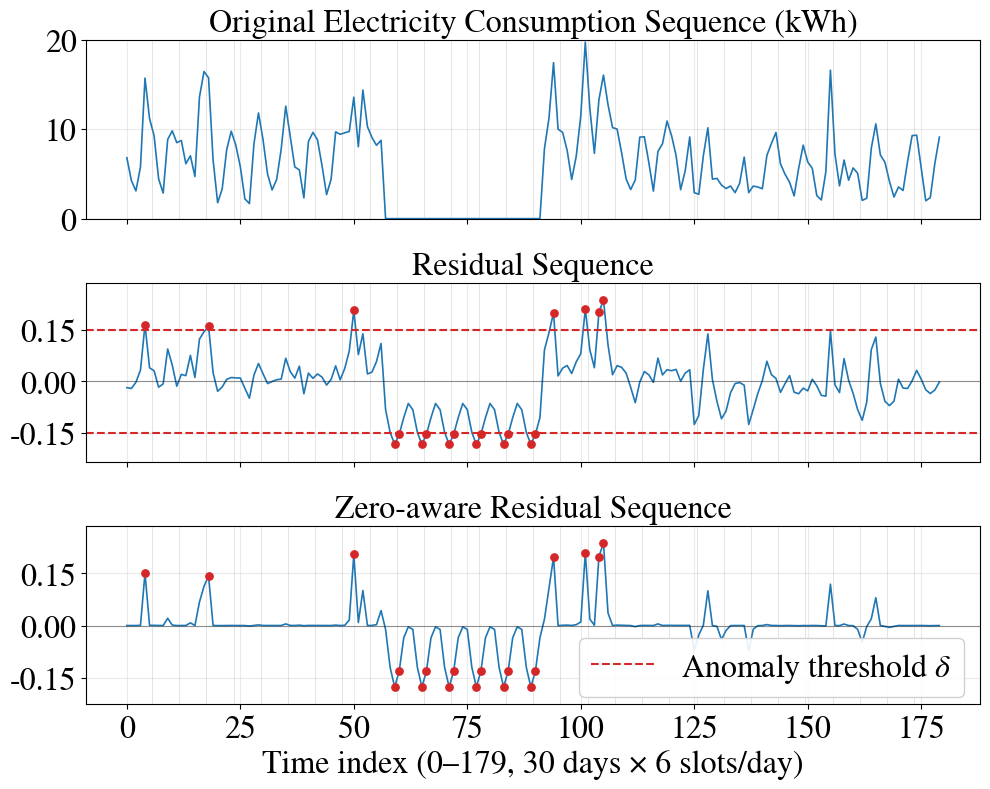

sampled_idx=3727


In [62]:
sampled_index = 7938  # 指定样本索引；设为 None 则随机抽取

fig, axes, sampled_idx = plot_anomaly_pack_sample(
    data_raw,
    data_r,
    data_f,
    sample_idx=3727,
    threshold=0.15,
    figsize=(10, 8),
    title_fontsize=23,
    label_fontsize=23,
    tick_fontsize=23,
    y_pad_n_data=2.0,
    y_pad_n_residual=0.05,
    save_path = '../../Plot/Appendix/datasetvisualization/anomaly_visualization.png',
)
print(f"sampled_idx={sampled_idx}")